In [1]:
%matplotlib inline
import numpy as np
import cv2
import matplotlib.pyplot as plt

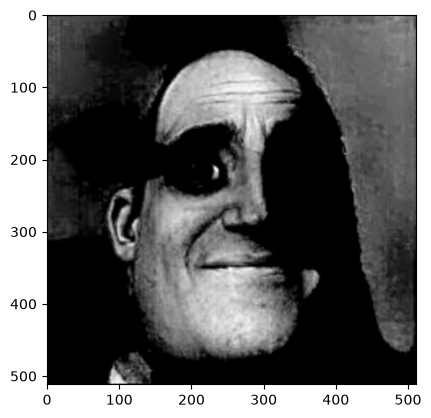

In [2]:
image_bgr = cv2.imread('img.jpg')
gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
gray = cv2.resize(gray, (512, 512), interpolation=cv2.INTER_AREA)
plt.imshow(gray, cmap="gray")

In [3]:
# одна ступень 2D-преобразования Хаара
def haar_2d(img):
    img = img.astype(np.float32)
    h, w = img.shape
    assert h % 2 == 0 and w % 2 == 0

    # строки
    a, b = img[0::2, :], img[1::2, :]
    L, H = (a + b) * 0.5, (a - b) * 0.5
    rows = np.vstack([L, H])

    # столбцы
    L_rows, H_rows = rows[:h // 2, :], rows[h // 2:, :]
    a, b = L_rows[:, 0::2], L_rows[:, 1::2]
    LL, LH = (a + b) * 0.5, (a - b) * 0.5
    a, b = H_rows[:, 0::2], H_rows[:, 1::2]
    HL, HH = (a + b) * 0.5, (a - b) * 0.5

    out = np.zeros((h, w), dtype=np.float32)
    out[: h // 2, : w // 2] = LL
    out[: h // 2, w // 2:]  = LH
    out[h // 2:, : w // 2]  = HL
    out[h // 2:, w // 2:]   = HH
    return out, LL

In [4]:
# три ступени
current = gray.copy()
LL_levels = []
decompositions = []
for lvl in range(3):
    out, LL = haar_2d(current)
    decompositions.append(out)
    LL_levels.append(LL)
    current = LL

for i, ll in enumerate(LL_levels):
    print(f"LL{i+1}: {ll.shape}, min={ll.min():.1f}, max={ll.max():.1f}")

LL1: (256, 256), min=0.0, max=246.8
LL2: (128, 128), min=0.0, max=243.2
LL3: (64, 64), min=0.0, max=238.6


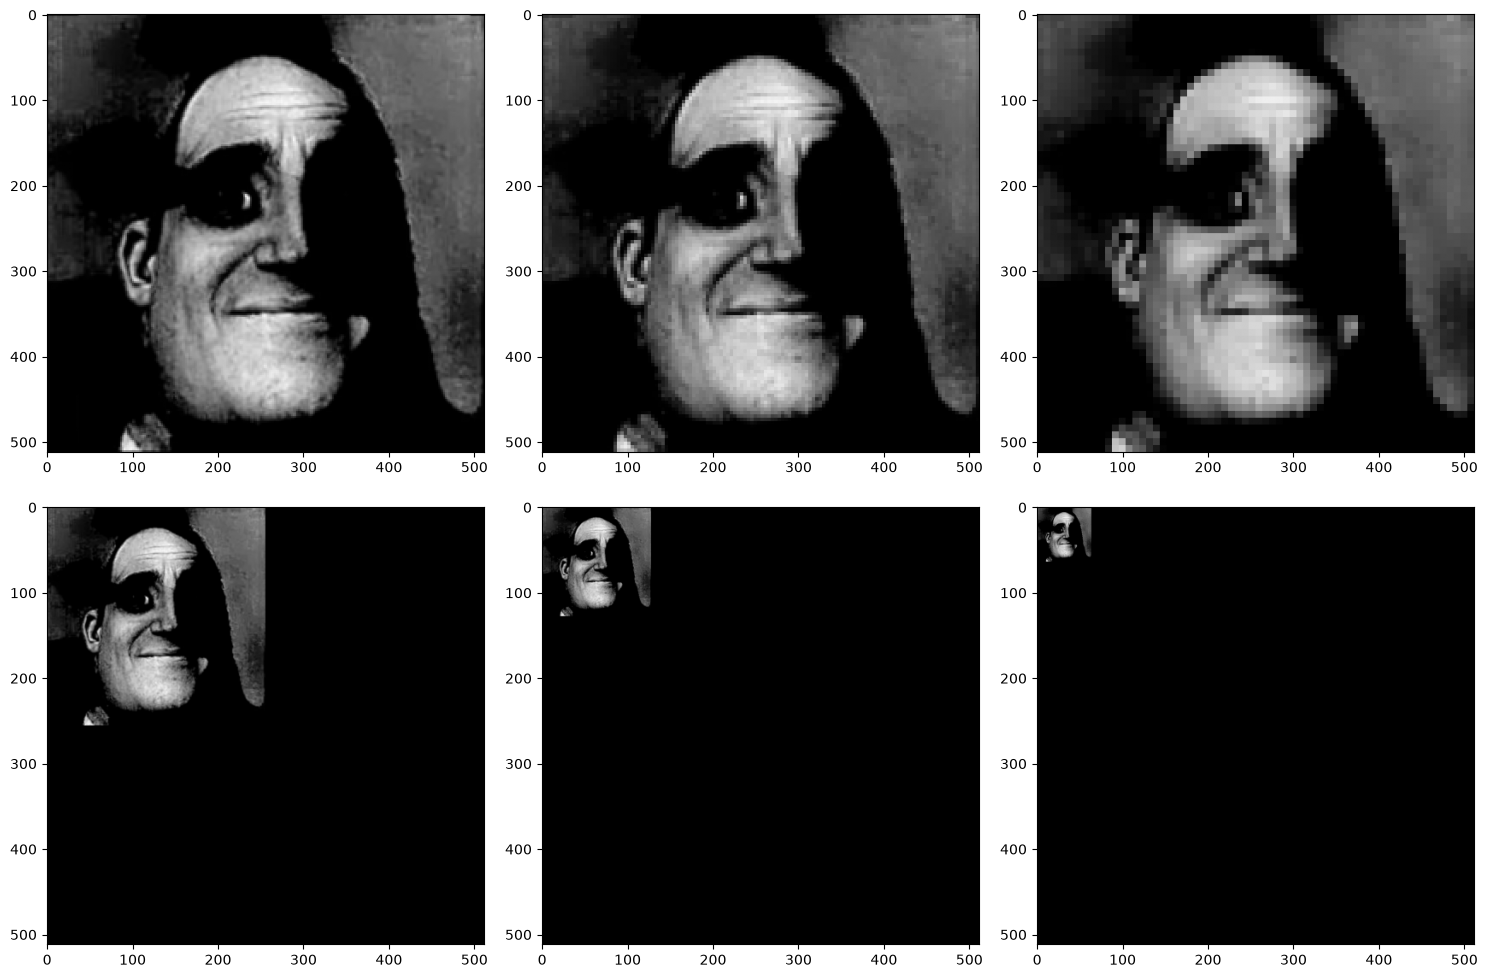

In [5]:
# визуализация
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for i, ll in enumerate(LL_levels):
    big = cv2.resize(ll, (512, 512), interpolation=cv2.INTER_NEAREST)
    axes[0, i].imshow(big, cmap='gray', vmin=0, vmax=255)

for i, ll in enumerate(LL_levels):
    canvas = np.zeros((512, 512), dtype=np.float32)
    h, w = ll.shape
    canvas[:h, :w] = ll
    axes[1, i].imshow(canvas, cmap='gray', vmin=0, vmax=255)

plt.tight_layout()
plt.show()